# 01 - EDA e qualidade dos dados
Chaves, duplicidades, nulos, integridade referencial, cobertura temporal.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 200, 'display.max_columns', 50)


In [2]:
from src.data_loader import load
B = {n: load(n) for n in ['base_cadastral','base_submissao','historico_emprestimos','historico_parcelas']}
for n, d in B.items(): print(n, d.shape, '| nulos>5%:', d.isna().mean()[lambda x: x>0.05].round(2).to_dict())

base_cadastral (50000, 16) | nulos>5%: {'ocupacao': 0.31}
base_submissao (50000, 8) | nulos>5%: {}
historico_emprestimos (211944, 37) | nulos>5%: {'data_liberacao': 0.96, 'data_primeiro_vencimento': 0.42, 'data_ultimo_vencimento_original': 0.45, 'data_ultimo_vencimento': 0.54, 'data_encerramento': 0.55, 'valor_bem': 0.23, 'valor_parcela': 0.24, 'valor_entrada': 0.54, 'percentual_entrada': 0.54, 'qtd_parcelas_planejadas': 0.24, 'taxa_juros_padrao': 1.0, 'taxa_juros_promocional': 1.0, 'acompanhantes_cliente': 0.49, 'indicador_seguro_contratado': 0.4}
historico_parcelas (1664384, 8) | nulos>5%: {}


In [3]:
e, p, s, c = B['historico_emprestimos'], B['historico_parcelas'], B['base_submissao'], B['base_cadastral']
print(e.status_contrato.value_counts())
print('contratos de parcelas sem emprestimo:', (~p.id_contrato.isin(e.id_contrato)).sum())
print('submissao sem cadastro:', (~s.id_cliente.isin(c.id_cliente)).sum(), '| sem historico:', round((~s.id_cliente.isin(e.id_cliente)).mean(),3))
print('parcelas duplicadas (contrato,parcela,versao):', p.duplicated(['id_contrato','numero_parcela','versao_parcela']).sum(), '| sem pagamento:', p.data_real_pagamento.isna().sum())

status_contrato
aprovado                131735
cancelado                40266
recusado                 36359
oferta nao utilizada      3584
Name: count, dtype: int64
contratos de parcelas sem emprestimo: 0


submissao sem cadastro: 0 | sem historico: 0.041


parcelas duplicadas (contrato,parcela,versao): 79945 | sem pagamento: 3655


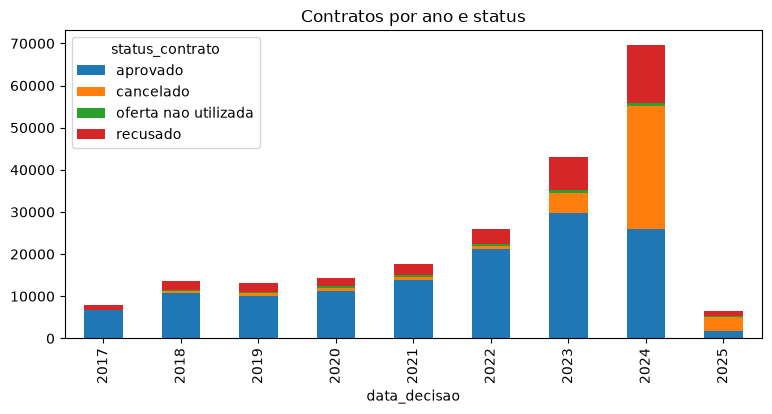

count        49669.0
mean        200627.0
std         981122.0
min          16500.0
25%         112500.0
50%         148500.0
75%         202500.0
max      117000000.0
Name: renda_anual, dtype: float64
sexo
feminino         32426
masculino        17523
nao informado       51
Name: count, dtype: int64


In [4]:
e.groupby(e.data_decisao.dt.year).status_contrato.value_counts().unstack().plot(kind='bar', stacked=True, title='Contratos por ano e status', figsize=(9,4)); plt.show()
print(c.renda_anual.describe().round(0))
print(c.sexo.value_counts())